# 02. The fork: v2.3

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import dfoct
from dfoct import analysis as an

FIGURES = ROOT / "figures"
FIGURES.mkdir(exist_ok=True)
R = an.load()
problems = {(s, a): dfoct.load_problem(p, s, a) for p, s, a in dfoct.SETTINGS}
pd.options.display.float_format = "{:.3g}".format

## What v2.3 changes

In [2]:
pd.DataFrame({
    "v1.3 (DFO-TR's search)": {"start": "uniform on [0, 255]", "disturbance": "uniform on [0, 255]", "rate Δ": dfoct.V1_3.delta},
    "v2.3": {"start": f"flat level ± {dfoct.V2_3.spread:g}", "disturbance": f"best fly's value ± {dfoct.V2_3.radius:g}", "rate Δ": dfoct.V2_3.delta},
})

,v1.3 (DFO-TR's search),v2.3
start,"uniform on [0, 255]",flat level ± 16
disturbance,"uniform on [0, 255]",best fly's value ± 0.05
rate Δ,0.001,0.003


## Where a moved pixel can land (one pixel; best fly 120, other fly 100)

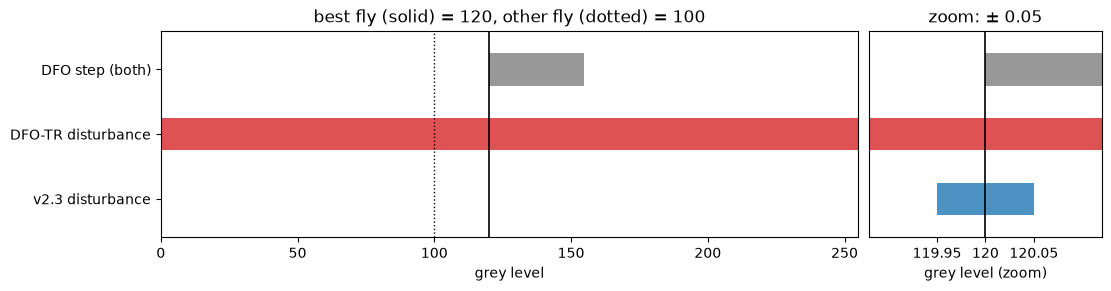

In [3]:
s_, i_, r_ = 120.0, 100.0, dfoct.V2_3.radius
rows_ = [("DFO step (both)", (s_, s_ + np.sqrt(3) * (s_ - i_)), "#7f7f7f"),
         ("DFO-TR disturbance", (0.0, 255.0), "#d62728"), ("v2.3 disturbance", (s_ - r_, s_ + r_), "#1f77b4")]
fig, axes = plt.subplots(1, 2, figsize=(11, 2.8), layout="constrained", gridspec_kw={"width_ratios": [3, 1]})
for ax, lim in zip(axes, [(0, 255), (s_ - 0.12, s_ + 0.12)]):
    for k, (n, (lo, hi), c) in enumerate(rows_):
        ax.barh(k, hi - lo, left=lo, height=0.5, color=c, alpha=0.8)
    ax.axvline(s_, color="black", lw=1.2)
    ax.axvline(i_, color="black", lw=1.0, ls=":")
    ax.set_xlim(*lim)
    ax.set_ylim(2.6, -0.6)
axes[0].set_yticks(range(3), [n for n, _r, _c in rows_])
axes[0].set(xlabel="grey level", title="best fly (solid) = 120, other fly (dotted) = 100")
axes[1].set_yticks([])
axes[1].set_xticks([s_ - r_, s_, s_ + r_], [f"{s_ - r_:g}", f"{s_:g}", f"{s_ + r_:g}"])
axes[1].set(xlabel="grey level (zoom)", title=f"zoom: ± {r_:g}")
fig.savefig(FIGURES / "mutation.pdf", bbox_inches="tight")

## The fork in clonal-selection terms (CLONALG, de Castro & Von Zuben 2002)

In [4]:
immune = pd.DataFrame([
    ("best fly s", "highest-affinity antibody", "match"),
    ("other fly i", "its clone", "match"),
    ("e1 (lower is better)", "affinity (higher is better)", "match"),
    ("keep the better of the two", "selection", "match"),
    ("disturbance ± 0.05 around s, Δ = 0.003", "somatic hypermutation", "partial: CLONALG's rate falls as affinity rises; fixed here"),
    ("DFO-TR's disturbance U(0, 255)", "receptor editing / new random cells", "partial: CLONALG adds cells every generation"),
    ("N = 2", "population; the n best are cloned", "partial: a population of two"),
    ("DFO step towards s", "--", "none"),
    ("clean start ℓ ± 16", "--", "none: problem knowledge"),
], columns=["v2.3", "CLONALG", "fit"]).set_index("v2.3")
an.to_tex(immune, FIGURES / "tab_immune.tex")
immune

,CLONALG,fit
v2.3,,
best fly s,highest-affinity antibody,match
other fly i,its clone,match
e1 (lower is better),affinity (higher is better),match
keep the better of the two,selection,match
"disturbance ± 0.05 around s, Δ = 0.003",somatic hypermutation,partial: CLONALG's rate falls as affinity rise...
"DFO-TR's disturbance U(0, 255)",receptor editing / new random cells,partial: CLONALG adds cells every generation
N = 2,population; the n best are cloned,partial: a population of two
DFO step towards s,--,none
clean start ℓ ± 16,--,none: problem knowledge


## One change at a time (1M FEs, median of 10 seeds)

In [5]:
tun = R["tuning"]
steps = ["v1.3", "clean start ±16", "restart ±1", "restart ±0.25", "v2.3"]
med = tun.groupby(["method", "size", "alpha"]).psnr.median()
ladder = pd.DataFrame({an.label(s, a): [med[(m, s, a)] for m in steps] for s, a in an.settings()}, index=steps)
ladder.loc["SIRT-box"] = [R["sirt"].set_index(["size", "alpha"]).psnr[(s, a)] for s, a in an.settings()]
ladder_table = pd.concat({"median PSNR (dB)": ladder, "gain over the row above": ladder.diff().iloc[:-1]}, axis=1)
an.to_tex(ladder, FIGURES / "tab_ladder.tex")
ladder_table.round(2)

median PSNR (dB)                                 \
                  32² / 6 angles 64² / 6 angles 32² / 32 angles   
v1.3                        13.2           11.8            20.8   
clean start ±16               14           12.1            21.6   
restart ±1                  19.1           16.5            35.8   
restart ±0.25                 20           17.3            37.7   
v2.3                        20.9           16.7            36.4   
SIRT-box                    22.7             19            71.5   

                gain over the row above                                 
                         32² / 6 angles 64² / 6 angles 32² / 32 angles  
v1.3                                NaN            NaN             NaN  
clean start ±16                    0.85           0.25            0.73  
restart ±1                         5.09           4.45            14.2  
restart ±0.25                      0.84           0.83            1.95  
v2.3                               0.94          -0.68           -1.28  
SIRT-box                            NaN            NaN             NaN

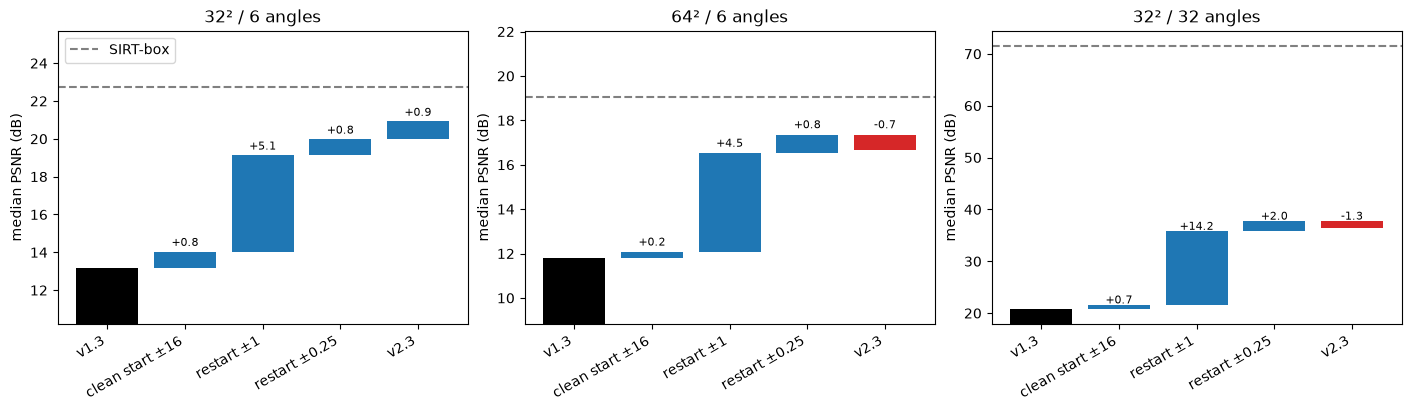

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), layout="constrained")
for ax, col in zip(axes, ladder.columns):
    v = ladder[col].iloc[:-1].to_numpy()
    prev = v[0]
    ax.bar(0, v[0], color="black")
    for k in range(1, len(v)):
        ax.bar(k, v[k] - prev, bottom=prev, color="#1f77b4" if v[k] >= prev else "#d62728")
        ax.text(k, max(v[k], prev) + 0.3, f"{v[k] - prev:+.1f}", ha="center", fontsize=8)
        prev = v[k]
    ax.axhline(ladder[col].iloc[-1], color="grey", ls="--", label="SIRT-box")
    ax.set_xticks(range(len(v)), steps, rotation=30, ha="right")
    ax.set(ylabel="median PSNR (dB)", title=col, ylim=(min(v) - 3, max(v.max(), ladder[col].iloc[-1]) + 3))
axes[0].legend(loc="upper left")
fig.savefig(FIGURES / "ladder.pdf", bbox_inches="tight")

## Where a disturbed pixel lands (±16 clean start, Δ = 0.001)

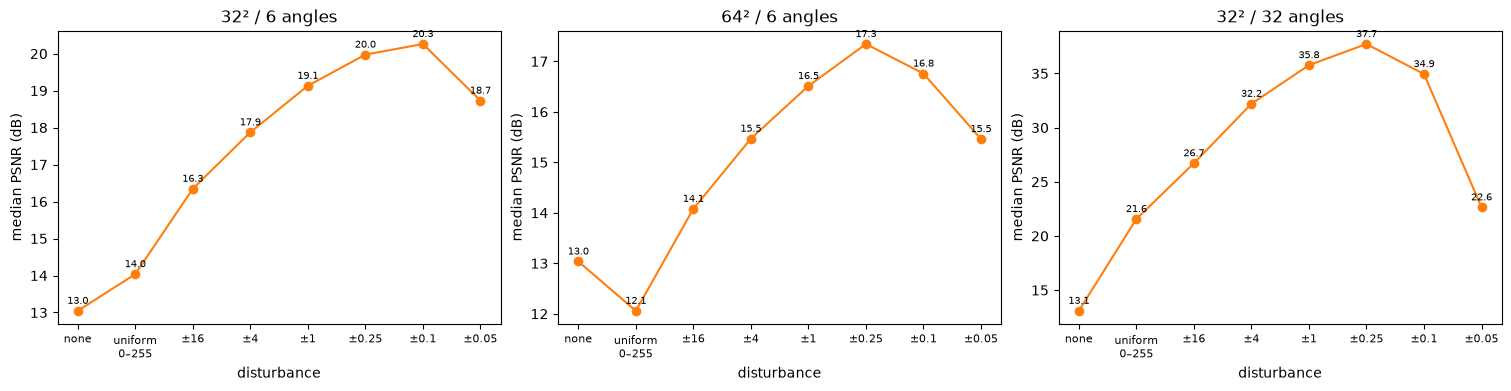

In [7]:
restarts = ["no restarts", "clean start ±16", "restart ±16", "restart ±4", "restart ±1", "restart ±0.25", "restart ±0.1", "restart ±0.05"]
names = ["none", "uniform\n0–255", "±16", "±4", "±1", "±0.25", "±0.1", "±0.05"]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), layout="constrained")
for ax, (s, a) in zip(axes, an.settings()):
    v = [med[(m, s, a)] for m in restarts]
    ax.plot(range(len(v)), v, "o-", color="#ff7f0e")
    for k, val in enumerate(v):
        ax.annotate(f"{val:.1f}", (k, val), xytext=(0, 5), textcoords="offset points", ha="center", fontsize=7)
    ax.set_xticks(range(len(v)), names, fontsize=8)
    ax.set(ylabel="median PSNR (dB)", title=an.label(s, a), xlabel="disturbance")
fig.savefig(FIGURES / "disturbance.pdf", bbox_inches="tight")

## Tuning: disturbance radius × rate (1M FEs, median of 10 seeds)

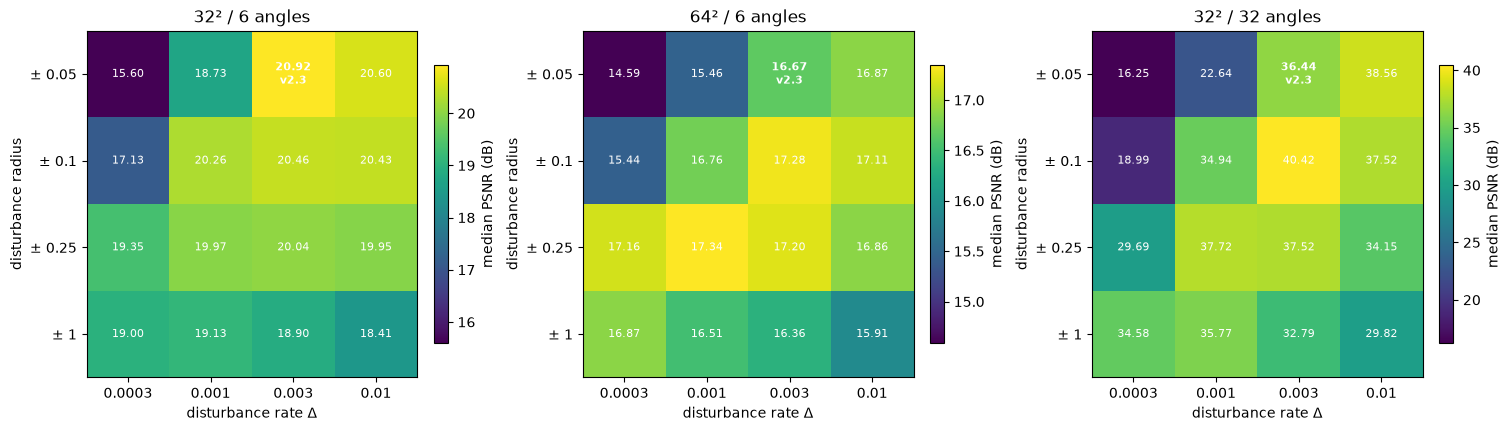

In [8]:
RADII, RATES = [0.05, 0.1, 0.25, 1.0], [0.0003, 0.001, 0.003, 0.01]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), layout="constrained")
for ax, (s, a) in zip(axes, an.settings()):
    z = np.array([[med[(f"±{r:g} Δ{d:g}", s, a)] for d in RATES] for r in RADII])
    im = ax.imshow(z, cmap="viridis", aspect="auto")
    for i, r in enumerate(RADII):
        for j, d in enumerate(RATES):
            pick = (r, d) == (dfoct.V2_3.radius, dfoct.V2_3.delta)
            ax.text(j, i, f"{z[i, j]:.2f}" + ("\nv2.3" if pick else ""), ha="center", va="center",
                    color="white", fontsize=8, fontweight="bold" if pick else "normal")
    ax.set_xticks(range(len(RATES)), [f"{d:g}" for d in RATES])
    ax.set_yticks(range(len(RADII)), [f"± {r:g}" for r in RADII])
    ax.set(xlabel="disturbance rate Δ", ylabel="disturbance radius", title=an.label(s, a))
    fig.colorbar(im, ax=ax, shrink=0.8, label="median PSNR (dB)")
fig.savefig(FIGURES / "grid.pdf", bbox_inches="tight")

In [9]:
grid = tun[tun.method.str.startswith("±")]
best = grid.groupby(["size", "alpha", "method"]).psnr.median().groupby(["size", "alpha"]).idxmax().map(lambda k: k[2])
pd.DataFrame({"best cell": best, "its median PSNR": grid.groupby(["size", "alpha", "method"]).psnr.median()[[(s, a, m) for (s, a), m in best.items()]].to_numpy()})

best cell  its median PSNR
size alpha                               
32   6      ±0.05 Δ0.003             20.9
     32      ±0.1 Δ0.003             40.4
64   6      ±0.25 Δ0.001             17.3

## v2.3 at work: the best image as the FEs grow (seed 0, 32² / 6 angles)

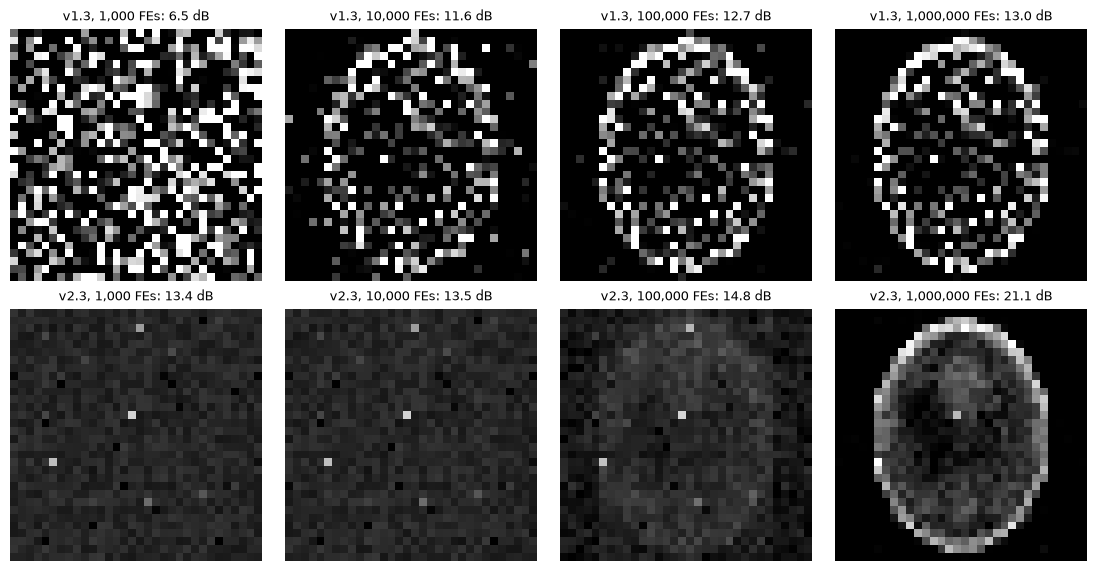

In [10]:
p = problems[(32, 6)]
cps = [1_000, 10_000, 100_000, 1_000_000]
runs = {m: dfoct.run(p, st, cps[-1], seed=0, checkpoints=cps) for m, st in dfoct.METHODS.items()}
fig, axes = plt.subplots(2, len(cps), figsize=(11, 5.6), layout="constrained")
for row, (m, r) in enumerate(runs.items()):
    for col, (c, x) in enumerate(zip(cps, r.snaps)):
        an.show(axes[row, col], x, 32, f"{m}, {c:,} FEs: {dfoct.score(p, x)['psnr']:.1f} dB")
fig.savefig(FIGURES / "progress_images.pdf", bbox_inches="tight")